# LSTM Indirect Net-Load Result — Fixed

This is a corrected notebook copy. The original notebook is not modified.
The cell order intentionally follows the original workflow: load data,
preprocess, build hourly sequences, split, train, evaluate, plot, and save.


## 1. Imports and configuration


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def find_project_root():
    """Find the repository root when Jupyter is launched from inside the repository."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing 'Data Download' and the method folders."
    )


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "Data Download"
FIXED_DATA_DIR = PROJECT_ROOT / "fixed_data"
DATA_FILE = FIXED_DATA_DIR / "ercot_2021_2024_hourly.csv"
OUTPUT_DIR = PROJECT_ROOT / "fixed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TIME_COLUMN = "time"


## 2. Load component predictions with timestamps


In [2]:
def read_predictions(filename, label):
    path = OUTPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {label} prediction file: {path}. "
            "Run the corresponding LSTM indirect component Notebook first."
        )
    frame = pd.read_excel(path)
    required = {TIME_COLUMN, "actual", "predict"}
    missing = required.difference(frame.columns)
    if missing:
        raise KeyError(f"{label} prediction file is missing: {sorted(missing)}")
    frame = frame[[TIME_COLUMN, "actual", "predict"]].copy()
    frame[TIME_COLUMN] = pd.to_datetime(frame[TIME_COLUMN], errors="raise")
    if frame[TIME_COLUMN].duplicated().any():
        raise ValueError(f"{label} predictions contain duplicate timestamps.")
    return frame.sort_values(TIME_COLUMN).reset_index(drop=True)


load_predictions = read_predictions("lstm_indirect_total_load_predictions.xlsx", "load")
solar_predictions = read_predictions("lstm_indirect_solar_generation_predictions.xlsx", "solar")
wind_predictions = read_predictions("lstm_indirect_wind_generation_predictions.xlsx", "wind")

time_sets = [
    frozenset(load_predictions[TIME_COLUMN]),
    frozenset(solar_predictions[TIME_COLUMN]),
    frozenset(wind_predictions[TIME_COLUMN]),
]
if not (time_sets[0] == time_sets[1] == time_sets[2]):
    raise ValueError(
        "Component test timestamps differ. Refusing positional or silent "
        "intersection-only net-load arithmetic."
    )
print("Common component test timestamps:", len(time_sets[0]))


Common component test timestamps: 1754


## 3. One-to-one timestamp merge and net-load identity audit


In [3]:
# Merge component predictions by timestamp before calculating net load.
merged = load_predictions.rename(
    columns={"actual": "load_actual", "predict": "load_predict"}
).merge(
    solar_predictions.rename(
        columns={"actual": "solar_actual", "predict": "solar_predict"}
    ),
    on=TIME_COLUMN,
    how="inner",
    validate="one_to_one",
).merge(
    wind_predictions.rename(
        columns={"actual": "wind_actual", "predict": "wind_predict"}
    ),
    on=TIME_COLUMN,
    how="inner",
    validate="one_to_one",
)
if len(merged) != len(load_predictions):
    raise ValueError("Component timestamp merge unexpectedly lost rows.")

merged["component_actual_net_load"] = (
    merged["load_actual"]
    - merged["solar_actual"]
    - merged["wind_actual"]
)
merged["predict"] = (
    merged["load_predict"]
    - merged["solar_predict"]
    - merged["wind_predict"]
)

# Use the exact canonical target produced from timestamp-aligned raw ERCOT files.
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Prepared data not found: {DATA_FILE}. "
        "Run Data Preparation/01_Prepare_Available_ERCOT_Data.ipynb first."
    )
canonical_net = pd.read_csv(
    DATA_FILE, usecols=[TIME_COLUMN, "net_load"], parse_dates=[TIME_COLUMN]
).rename(columns={"net_load": "actual"})
if canonical_net[TIME_COLUMN].duplicated().any():
    raise ValueError("Prepared canonical net load contains duplicate timestamps.")
merged = merged.merge(canonical_net, on=TIME_COLUMN, how="left", validate="one_to_one")
if merged["actual"].isna().any():
    raise ValueError("Canonical net load is missing prediction timestamps.")
merged["identity_error"] = merged["component_actual_net_load"] - merged["actual"]
print("Mean absolute net-load identity error (MW):", merged["identity_error"].abs().mean())
print("Maximum absolute net-load identity error (MW):", merged["identity_error"].abs().max())


Mean absolute net-load identity error (MW): 3.965687274321183e-12
Maximum absolute net-load identity error (MW): 2.1827872842550278e-11


## 4. Full common-test metrics


In [4]:
def regression_metrics(actual, predicted, mape_min_actual=1.0):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    mse = mean_squared_error(actual, predicted)
    variance = np.var(actual)
    denominator = np.abs(actual) + np.abs(predicted)
    smape = np.divide(
        2.0 * np.abs(error), denominator,
        out=np.zeros_like(denominator), where=denominator > 1e-9,
    )
    mask = np.abs(actual) > mape_min_actual
    return {
        "sample_count": len(actual),
        "mean_error_mw": np.mean(error),
        "mae_mw": mean_absolute_error(actual, predicted),
        "rmse_mw": np.sqrt(mse),
        "mse_mw2": mse,
        "nmse": mse / variance if variance > 1e-12 else np.nan,
        "r2": r2_score(actual, predicted),
        "smape_percent": np.mean(smape) * 100.0,
        "masked_mape_percent": (
            np.mean(np.abs(error[mask] / actual[mask])) * 100.0 if mask.any() else np.nan
        ),
    }


metrics = regression_metrics(merged["actual"], merged["predict"])
pd.Series(metrics)


sample_count             1754.000000
mean_error_mw             -83.893718
mae_mw                    695.457324
rmse_mw                   938.098414
mse_mw2                880028.634881
nmse                        0.012911
r2                          0.987089
smape_percent               2.484051
masked_mape_percent         2.463528
dtype: float64

## 5. Plot and save


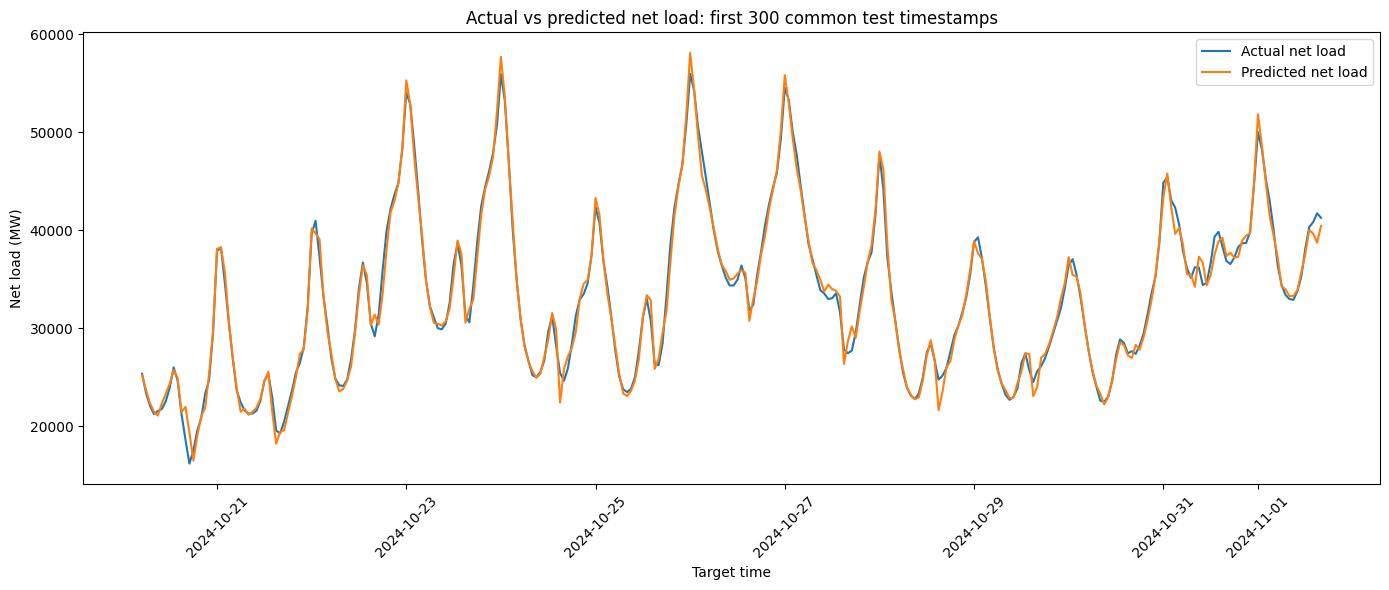

In [5]:
view = merged.iloc[:min(300, len(merged))].reset_index(drop=True)
sample_index = view.index.to_numpy()
paper_style = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
}
with plt.rc_context(paper_style):
    fig, ax = plt.subplots(figsize=(5.5, 2.7))
    ax.plot(sample_index, view["actual"], color="#1f77b4", linewidth=0.9, label="Actual Net Load")
    ax.plot(sample_index, view["predict"], color="#ff7f0e", linewidth=0.9, label="Predicted Net Load")
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Net Load (MW)")
    ax.set_xticks(range(0, len(view) + 1, 50))
    ax.grid(True, linestyle="--", linewidth=0.55, color="#bfbfbf", alpha=0.65)
    ax.legend(loc="upper right", frameon=True, fancybox=False, edgecolor="#bfbfbf", framealpha=1.0)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)
    ax.tick_params(direction="out", length=3.0, width=0.8, colors="black")
    fig.tight_layout(pad=0.5)
    figure_path = FIGURE_DIR / "Fig_11_LSTM_Indirect_Actual_vs_Predicted.png"
    fig.savefig(figure_path, dpi=600, bbox_inches="tight")
    print("Saved figure:", figure_path)
    plt.show()


In [ ]:
ARTIFACT_NAME = "lstm_indirect_net_load"
result_columns = [
    TIME_COLUMN, "actual", "predict", "component_actual_net_load", "identity_error",
    "load_actual", "load_predict", "solar_actual", "solar_predict",
    "wind_actual", "wind_predict",
]
results = merged[result_columns].copy()
results["error"] = results["predict"] - results["actual"]
results["absolute_error"] = results["error"].abs()
results.to_csv(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.csv", index=False)
results.to_excel(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx", index=False)
pd.Series(metrics).to_json(OUTPUT_DIR / f"{ARTIFACT_NAME}_metrics.json", indent=2)
print("Saved:", OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx")
